# Linear static analysis

A linear static analysis solves the equilibrium equations
$\boldsymbol{K} \boldsymbol{u} = \boldsymbol{f}$ for the displacement vector
$\boldsymbol{u}$, with the stiffness matrix $\boldsymbol{K}$ and the external
force vector $\boldsymbol{f}$. This example solves them with the function
[solve](../static.rst), the function [static](../static.rst) and the class
[Analysis](../analysis.rst), for the bar of Bathe (2014), Example 3.22,
whose exact solution is known.

**Reference.** Bathe, K.J., Finite Element Procedures, 2nd ed., K.J. Bathe,
Watertown, MA, 2014: Example 3.22 (pp. 120-122) and Example 4.5
(pp. 167-168).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix, csc_matrix

from structsolve import Analysis, solve, static

## The bar of Bathe's Example 3.22

The bar is fixed at $x = 0$ and loaded by the force $R = 100$ N at its end
$x = 180$ cm. Its cross-sectional area is $A = 1$ cm$^2$ in the part AB,
$0 \le x \le 100$ cm, and $A = (1 + (x - 100)/40)^2$ cm$^2$ in the part BC,
$100 \le x \le 180$ cm. The exact displacements are (Bathe 2014, Example 3.22,
p. 121)

$$
u(x) = \frac{100\,x}{E}, \quad 0 \le x \le 100; \qquad
u(x) = \frac{10000}{E} + \frac{4000}{E} - \frac{4000}{E\,(1 + (x - 100)/40)},
\quad 100 \le x \le 180
$$

with Young's modulus $E$; the axial force is $R = 100$ N everywhere. The
results below are given as $E u$, in N/cm, i.e. with $E = 1$.

The finite element model uses two-node bar elements with linear
displacements, as in Bathe's Example 4.5. The stiffness matrix of an
element between $x_1$ and $x_2$, of length $l = x_2 - x_1$, is

$$
\boldsymbol{k}_e = \frac{E}{l^2} \int_{x_1}^{x_2} A \,\mathrm{d}x
\begin{bmatrix} 1 & -1 \\ -1 & 1 \end{bmatrix}
$$

with the integral of the area evaluated exactly. The part AB, of constant
area, is one element; the part BC is divided into `nBC` elements.

In [2]:
E = 1.     # results are E*u
R = 100.   # N


def area_integral(x1, x2):
    # exact integral of the cross-sectional area A(x) from x1 to x2, cm^3
    if x2 <= 100.:
        return x2 - x1
    s1, s2 = x1 - 100., x2 - 100.
    return 40/3*((1 + s2/40)**3 - (1 + s1/40)**3)


def bar_model(nBC):
    # nodes, stiffness matrix with all dofs and force vector
    x = np.concatenate(([0.], np.linspace(100., 180., nBC + 1)))
    n = x.size
    K = lil_matrix((n, n))
    for e in range(n - 1):
        x1, x2 = x[e], x[e + 1]
        k = E*area_integral(x1, x2)/(x2 - x1)**2
        K[e:e+2, e:e+2] += k*np.array([[1., -1.], [-1., 1.]])
    f = np.zeros(n)
    f[-1] = R
    return x, K, f


def u_exact(x):
    x = np.asarray(x, dtype=float)
    s = np.maximum(x - 100., 0.)
    return np.where(x <= 100., R*x/E,
                    10000/E + 4000/E - 4000/(E*(1 + s/40)))

With two elements, the stiffness matrix of all degrees of freedom
$\boldsymbol{U}^\top = [U_1\ U_2\ U_3]$ is that of Bathe's Example 4.5
(p. 168, Eq. (a)),
$\boldsymbol{K} = \frac{E}{240} \begin{bmatrix} 2.4 & -2.4 & 0 \\
-2.4 & 15.4 & -13 \\ 0 & -13 & 13 \end{bmatrix}$:

In [3]:
x, K, f = bar_model(nBC=1)
print('240 K/E =')
print(np.round(240*K.toarray()/E, 10))

240 K/E =
[[  2.4  -2.4   0. ]
 [ -2.4  15.4 -13. ]
 [  0.  -13.   13. ]]


## Boundary conditions and solve

The matrix above is singular: the bar is free to move as a rigid body. The
fixed end $U_1 = 0$ is imposed by zeroing the row and the column of $U_1$.
[solve](../static.rst) removes the null rows and columns before solving with
`scipy.sparse.linalg.spsolve`, and returns zero at the removed degrees of
freedom; the force at a removed degree of freedom is ignored. The model of
two elements is Bathe's Ritz analysis with the displacement assumption (c),
which gives $u_B = 10000/E$ and $u_C = 11846.2/E$ (Bathe 2014, Example 3.22,
p. 122; Example 4.5 shows that it is the finite element model).

In [4]:
def fix_first_dof(K):
    K = K.tolil(copy=True)
    K[0, :] = 0.
    K[:, 0] = 0.
    return csc_matrix(K)


Kc = fix_first_dof(K)
u = solve(Kc, f, silent=True)
print('E u at the nodes x =', x, 'cm:', u)

print()
print(f'{"":5s} {"structsolve":>12s} {"Bathe p.122":>12s} {"rel. diff.":>10s}'
      f' {"exact p.121":>12s} {"rel. diff.":>10s}')
for name, ui, ref in [('u_B', u[1], 10000.), ('u_C', u[2], 11846.2)]:
    xi = 100. if name == 'u_B' else 180.
    ex = u_exact(xi)
    print(f'{name:5s} {ui:12.1f} {ref:12.1f} {abs(ui - ref)/ref:10.1e}'
          f' {ex:12.1f} {abs(ui - ex)/ex:10.1e}')

E u at the nodes x = [  0. 100. 180.] cm: [    0.         10000.         11846.15384615]

       structsolve  Bathe p.122 rel. diff.  exact p.121 rel. diff.
u_B        10000.0      10000.0    1.6e-15      10000.0    1.6e-15
u_C        11846.2      11846.2    3.9e-06      12666.7    6.5e-02


The structsolve solution reproduces Bathe's values to the digits he
printed. The part AB is exact with one element, since the axial force,
$R$ in every element, and the area are constant there; the displacement of
C is lower than the exact one, because the element stiffness above, with
the mean area, is higher than the exact stiffness of the tapered part.

## Mesh refinement

The tip displacement $u_C$ converges to the exact value as the part BC is
divided into more elements:

In [5]:
nBCs = [1, 2, 4, 8, 16, 32, 64]
uC = []
for nBC in nBCs:
    x, K, f = bar_model(nBC)
    uC.append(solve(fix_first_dof(K), f, silent=True)[-1])
uC = np.array(uC)
uC_exact = u_exact(180.)
err = abs(uC - uC_exact)/uC_exact

print(f'{"nBC":>4s} {"E u_C":>12s} {"exact":>12s} {"rel. diff.":>10s}'
      f' {"observed order":>15s}')
for i, nBC in enumerate(nBCs):
    order = '' if i == 0 else f'{np.log(err[i-1]/err[i])/np.log(2):15.2f}'
    print(f'{nBC:4d} {uC[i]:12.4f} {uC_exact:12.4f} {err[i]:10.2e} {order}')

 nBC        E u_C        exact rel. diff.  observed order
   1   11846.1538   12666.6667   6.48e-02 
   2   12345.8647   12666.6667   2.53e-02            1.35
   4   12568.9854   12666.6667   7.71e-03            1.72
   8   12640.5760   12666.6667   2.06e-03            1.90
  16   12660.0221   12666.6667   5.25e-04            1.97
  32   12664.9975   12666.6667   1.32e-04            1.99
  64   12666.2489   12666.6667   3.30e-05            2.00


The observed order of convergence,
$\log_2$ of the ratio of the relative differences of two successive meshes,
approaches 2: the relative difference decreases by a factor of about four
when the element length is halved. The
displacements along the bar:

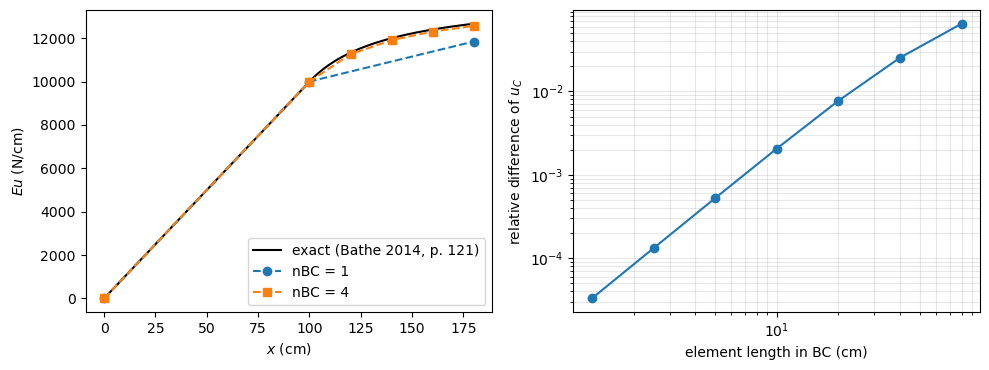

In [6]:
xx = np.linspace(0., 180., 361)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(xx, u_exact(xx), 'k-', label='exact (Bathe 2014, p. 121)')
for nBC, mk in [(1, 'o--'), (4, 's--')]:
    x, K, f = bar_model(nBC)
    u = solve(fix_first_dof(K), f, silent=True)
    axes[0].plot(x, u, mk, label=f'nBC = {nBC}')
axes[0].set_xlabel('$x$ (cm)')
axes[0].set_ylabel('$E u$ (N/cm)')
axes[0].legend()
axes[1].loglog(80./np.array(nBCs), err, 'o-')
axes[1].set_xlabel('element length in BC (cm)')
axes[1].set_ylabel('relative difference of $u_C$')
axes[1].grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

## static and Analysis

[static](../static.rst) solves the same system with [solve](../static.rst)
and returns the load factor `[1.]` and the list of solutions. The class
[Analysis](../analysis.rst) receives callables that calculate the external
force vector and the stiffness matrix, here of the model with
`nBC = 16`; its method `static` with `NLgeom=False` runs a linear analysis,
stored in the attributes `increments` and `cs`. Both give the solution of
[solve](../static.rst):

In [7]:
x, K, f = bar_model(nBC=16)
Kc = fix_first_dof(K)

u_solve = solve(Kc, f, silent=True)

increments, cs = static(Kc, f, silent=True)
u_static = cs[0]


def calc_fext(inc=1., silent=True):
    return inc*f


def calc_kC(c=None, NLgeom=False, silent=True):
    return Kc


an = Analysis(calc_fext=calc_fext, calc_kC=calc_kC)
an.static(NLgeom=False, silent=True)
u_analysis = an.cs[-1]

print('static: increments =', increments)
print('Analysis: increments =', an.increments)
print()
print(f'{"function":10s} {"E u_C":>12s} {"exact":>12s} {"rel. diff.":>10s}'
      f' {"max |u - u_solve|":>18s}')
for name, ui in [('solve', u_solve), ('static', u_static),
                 ('Analysis', u_analysis)]:
    print(f'{name:10s} {ui[-1]:12.4f} {uC_exact:12.4f}'
          f' {abs(ui[-1] - uC_exact)/uC_exact:10.2e}'
          f' {np.abs(ui - u_solve).max():18.1e}')

static: increments = [1.0]
Analysis: increments = [1.0]

function          E u_C        exact rel. diff.  max |u - u_solve|
solve        12660.0221   12666.6667   5.25e-04            0.0e+00
static       12660.0221   12666.6667   5.25e-04            0.0e+00
Analysis     12660.0221   12666.6667   5.25e-04            0.0e+00
